<a href="https://colab.research.google.com/github/muhammadabdullahz/industrial-production-ridge-lasso/blob/main/RL_final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## The Data

The data come from FRED-MD (McCracken and Ng), a monthly database of U.S. macroeconomic indicators maintained by the Federal Reserve Bank of St. Louis. This project uses the September 2026 vintage: 812 monthly observations from January 1959 to August 2026 on 126 series, covering eight groups (output, labor market, housing, consumption and orders, money and credit, interest and exchange rates, prices, and the stock market).

The database authors assign each series a transformation code that converts it to a stationary form, such as growth rates for most activity series and first differences for interest rates. The target is future growth in industrial production (`INDPRO`), and the remaining series are used as predictors.

Five series have missing values, mostly because they begin later than 1959. Series with more than 10% of observations missing are dropped, and any remaining rows with missing values are removed after transformation. No values are filled in, to avoid using future information.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
raw = pd.read_csv('https://raw.githubusercontent.com/mabdullahecon/industrial-production-ridge-lasso/refs/heads/main/2026-09-MD.csv')
raw.head()

,sasdate,RPI,W875RX1,DPCERA3M086SBEA,CMRMTSPLx,RETAILx,INDPRO,IPFPNSS,IPFINAL,IPCONGD,...,DNDGRG3M086SBEA,DSERRG3M086SBEA,CES0600000008,CES2000000008,CES3000000008,UMCSENTx,DTCOLNVHFNM,DTCTHFNM,INVEST,VIXCLSx
0,Transform:,5.000,5.0,5.000,5.0000,5.00000,5.0000,5.0000,5.0000,5.0000,...,6.000,6.000,6.00,6.00,6.00,2.0,6.0,6.0,6.0000,1.0
1,1/1/1959,2583.560,2426.0,15.188,276676.8154,17689.23968,21.9998,23.6312,22.5507,32.1377,...,18.294,10.152,2.13,2.45,2.04,NaN,6476.0,12298.0,84.2043,NaN
2,2/1/1959,2593.596,2434.8,15.346,278713.9773,17819.01912,22.4306,23.9501,22.7461,32.3734,...,18.302,10.167,2.14,2.46,2.05,NaN,6476.0,12298.0,83.5280,NaN
3,3/1/1959,2610.396,2452.7,15.491,277775.2539,17967.91336,22.7538,24.0951,22.8577,32.3734,...,18.289,10.185,2.15,2.45,2.07,NaN,6508.0,12349.0,81.6405,NaN
4,4/1/1959,2627.446,2470.0,15.435,283362.7075,17978.97983,23.2384,24.4431,23.1926,32.8841,...,18.300,10.221,2.16,2.47,2.08,NaN,6620.0,12484.0,81.8099,NaN


In [ ]:
row = raw.iloc[0]
row.head()

,0
sasdate,Transform:
RPI,5.0
W875RX1,5.0
DPCERA3M086SBEA,5.0
CMRMTSPLx,5.0


In [ ]:
series = row.drop('sasdate')
tcodes = series.astype(int).to_dict()

In [ ]:
data = raw.iloc[1:].copy()
data['sasdate'] = pd.to_datetime(data['sasdate'])
data = data.set_index('sasdate')

In [ ]:
print(data.shape)
print(data.index.min(), data.index.max())
print(data['INDPRO'].head())
print(data.isna().sum().sort_values(ascending = False).head())
print(data.dtypes.value_counts())

(812, 126)
1959-01-01 00:00:00 2026-08-01 00:00:00
sasdate
1959-01-01    21.9998
1959-02-01    22.4306
1959-03-01    22.7538
1959-04-01    23.2384
1959-05-01    23.5885
Name: INDPRO, dtype: float64
ACOGNO           398
TWEXAFEGSMTHx    168
UMCSENTx         154
ANDENOx          109
VIXCLSx           42
dtype: int64
float64    109
int64       17
Name: count, dtype: int64


According to the Appendix, the transformation function maps raw FRED-MD macroeconomic series into stationary inputs using specific transformation codes assigned to each variable $x_t$.

Code 1 leaves the series in its raw level as $x_t$.

Code 2 applies a first difference given by $\Delta x_t = x_t - x_{t-1}$.

Code 3 applies a second difference given by $\Delta^2 x_t = (x_t - x_{t-1}) - (x_{t-1} - x_{t-2})$.

Code 4 applies a natural logarithm given by $\log(x_t)$.

Code 5 computes the first difference of the natural logarithm given by $\Delta \log(x_t) = \log(x_t) - \log(x_{t-1})$.

Code 6 computes the second difference of the natural logarithm given by $\Delta^2 \log(x_t) = \Delta \log(x_t) - \Delta \log(x_{t-1})$.

Code 7 computes the first difference of the simple percentage rate of change given by $\Delta(x_t / x_{t-1} - 1.0) = (x_t / x_{t-1} - 1) - (x_{t-1} / x_{t-2} - 1)$.

In [ ]:
# Transformation functions
def transform(x, tcode):
    if tcode == 1:
      return x
    elif tcode == 2:
      return x.diff()
    elif tcode == 3:
      return x.diff().diff()
    elif tcode == 4:
      return np.log(x)
    elif tcode == 5:
      return np.log(x).diff()
    elif tcode == 6:
      return np.log(x).diff().diff()
    elif tcode == 7:
      return ((x / x.shift(1)) - 1).diff()
    else:
      raise ValueError(f"Unknown tcode: {tcode}")

In [ ]:
transformed = pd.DataFrame({
    col: transform(data[col], tcodes[col])
    for col in data.columns
})

In [ ]:
print(transformed.shape)                                 # same as data.shape
set(tcodes) == set(data.columns)                   # True
transformed.isna().sum().sort_values(ascending=False).head(10)

(812, 126)


,0
ACOGNO,399
UMCSENTx,229
TWEXAFEGSMTHx,169
ANDENOx,110
VIXCLSx,42
PERMITW,12
PERMITMW,12
PERMITNE,12
PERMIT,12
PERMITS,12


The NaN counts are higher than before as differencing introduces a lot of missing values into the data. We now drop series with more than 10% missing values. We then drop the rows with any missing NaNs values.

In [ ]:
share_missing = transformed.isna().mean()
keep = share_missing[share_missing <= 0.10].index
transformed = transformed[keep]
clean = transformed.dropna()
print(clean.shape, clean.index.min(), clean.index.max())

(763, 122) 1962-07-01 00:00:00 2026-06-01 00:00:00


In [ ]:
dropped = [c for c in data.columns if c not in clean.columns]
print(dropped)

first = transformed[clean.columns].apply(lambda s: s.first_valid_index())
last  = transformed[clean.columns].apply(lambda s: s.last_valid_index())
print(first.sort_values().tail(5))   # which series start latest
print(last.sort_values().head(5))    # which series end earliest

['ACOGNO', 'ANDENOx', 'TWEXAFEGSMTHx', 'UMCSENTx']
PERMITMW   1960-01-01
PERMITNE   1960-01-01
PERMIT     1960-01-01
PERMITW    1960-01-01
VIXCLSx    1962-07-01
dtype: datetime64[ns]
S&P div yield   2026-06-01
ISRATIOx        2026-07-01
DTCTHFNM        2026-07-01
DTCOLNVHFNM     2026-07-01
CMRMTSPLx       2026-07-01
dtype: datetime64[ns]


We predict 3 months into the future so h=3 sets our forecast horizon. Our target variable is Industrial Production. It is a level series that grows exponentially over time. We measure percent growth over an h-month period using log differences.

In [ ]:
h = 3  # predicting 3 months into the future

log_ip = np.log(data["INDPRO"])
y_raw = 100 * (log_ip.shift(-h) - log_ip)

# Restrict to clean's date index and drop trailing NaNs caused by shift(-h)
y = y_raw.loc[clean.index].dropna()

# Align Feature Matrix (X) to match y's exact dates
X = clean.loc[y.index].copy()

In [ ]:
print("--- VERIFICATION CHECKS ---")
print(f"1. Raw INDPRO check: {data['INDPRO'].head(1).values[0]:.2f}")
print(f"2. Clean shape:                    {clean.shape}")
print(f"3. X shape:                        {X.shape}")
print(f"4. y shape:                        {y.shape}")
print(f"5. Do X and y shapes match?        {X.shape[0] == y.shape[0]}")
print(f"6. End date of y (should be -{h}m):  {y.index.max().strftime('%Y-%m')}")
print(f"7. Target units:                   Percent growth over next {h} months")

# Inspect the tail of y to confirm shift behavior
print("\nTail of y (Future IP Growth):")
print(y.tail())

--- VERIFICATION CHECKS ---
1. Raw INDPRO check: 22.00
2. Clean shape:                    (763, 122)
3. X shape:                        (762, 122)
4. y shape:                        (762,)
5. Do X and y shapes match?        True
6. End date of y (should be -3m):  2026-05
7. Target units:                   Percent growth over next 3 months

Tail of y (Future IP Growth):
sasdate
2026-01-01    1.512181
2026-02-01    0.717987
2026-03-01    1.083620
2026-04-01    0.454326
2026-05-01    0.416708
Name: INDPRO, dtype: float64


## Exploratory Data Analysis


### Chart 1 : Raw vs Transformed INDPRO

The left chart is a non-stationary level series. It exhibits a strong upward trend and non-constant mean over time. Running standard regression on raw level data causes spurious regression (fake correlations).

The right chart is a stationary series which is log-differenced. It fluctuates around a constant mean of zero, isolating monthly economic volatility - including the dramatic COVID 2020 shock spike / dip.

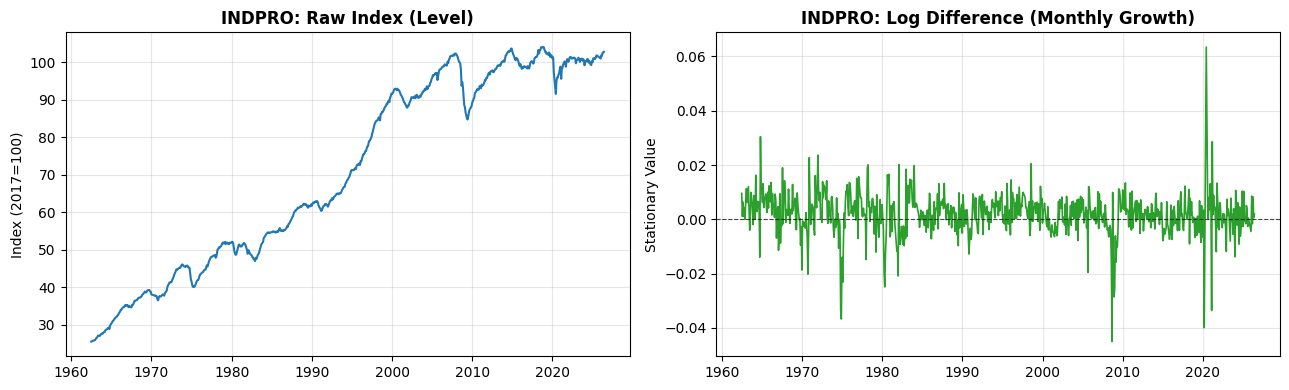

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(data.loc[clean.index, "INDPRO"], color="#1f77b4", linewidth=1.5)
axes[0].set_title("INDPRO: Raw Index (Level)", fontsize=12, fontweight='bold')
axes[0].set_ylabel("Index (2017=100)")
axes[0].grid(True, alpha=0.3)

axes[1].plot(clean["INDPRO"], color="#2ca02c", linewidth=1.2)
axes[1].axhline(0, color="black", linestyle="--", linewidth=0.8, alpha=0.7)
axes[1].set_title("INDPRO: Log Difference (Monthly Growth)", fontsize=12, fontweight='bold')
axes[1].set_ylabel("Stationary Value")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


### Chart 2: Histogram of the target Y

This chart shows the distribution of the target variable. Standard linear regression assumes normally distributed residuals. The distribution is centered slighly above zero, reflecting long-term post-war economic growth in US manufacturing. The extreme values highlight periods where the linear models face large prediction errors.





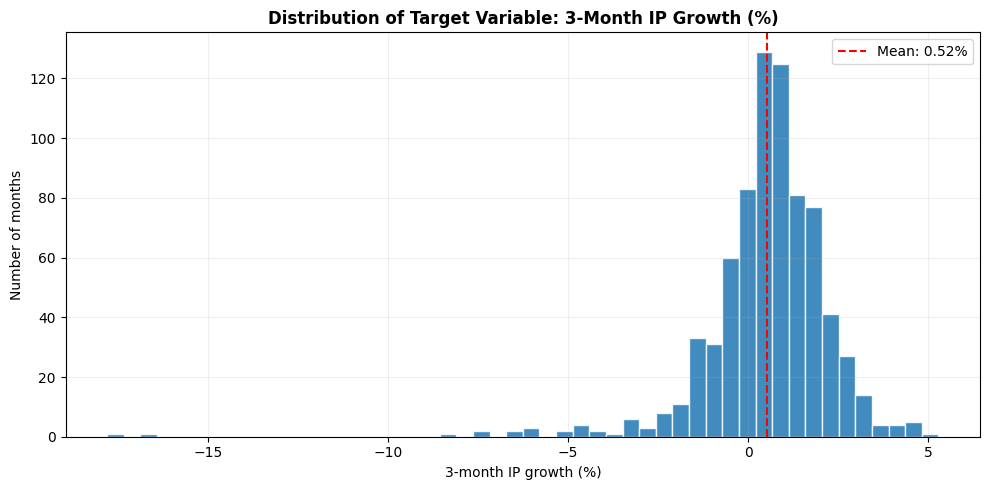

In [ ]:
plt.figure(figsize=(10, 5))
plt.hist(y, bins=50, edgecolor="white", color="#1f77b4", alpha=0.85)

mean_val = y.mean()
plt.axvline(mean_val, color="red", linestyle="--", linewidth=1.5, label=f"Mean: {mean_val:.2f}%")

plt.title("Distribution of Target Variable: 3-Month IP Growth (%)", fontsize=12, fontweight="bold")
plt.xlabel("3-month IP growth (%)")
plt.ylabel("Number of months")
plt.legend()
plt.grid(True, alpha=0.2)

plt.tight_layout()
plt.show()

In [ ]:
print("--- TOP 5 SMALLEST VALUES (Extremely Negative Growth) ---")
print(y.nsmallest(5))

print("\n--- TOP 5 LARGEST VALUES (Extremely Positive Growth) ---")
print(y.nlargest(5))

--- TOP 5 SMALLEST VALUES (Extremely Negative Growth) ---
sasdate
2020-01-01   -17.797130
2020-02-01   -16.492499
1974-10-01    -8.426470
1974-11-01    -7.398526
1974-09-01    -7.296642
Name: INDPRO, dtype: float64

--- TOP 5 LARGEST VALUES (Extremely Positive Growth) ---
sasdate
1964-10-01    5.288390
2020-06-01    4.664412
1980-08-01    4.560083
1971-11-01    4.514650
1978-01-01    4.440351
Name: INDPRO, dtype: float64


* Extreme Downside Outliers (2020 COVID-19 Shock): The largest negative 3-month growth rates occurred in early 2020 (2020-01-01 and 2020-02-01), where output contracted by over -16% to -17% due to global pandemic lockdowns and immediate economic shutdowns. The next severe downside cluster occurred during the 1973–1975 stagflation recession (late 1974), with quarterly contractions exceeding -7%.
* Extreme Upside Outliers (Post-Shock Rebounds): The highest positive growth rates reflect sharp historical economic recoveries, including late 1964, the initial post-lockdown reopening surge in June 2020 (+4.66%), and the post-recession rebound in August 1980 (+4.56%).

### Chart 3: Target Variable vs 2 predictors

Even famous leading economic indicators—like housing permits (PERMIT) or the term spread / yield curve (T10YFFM)—exhibit weak, noisy bivariate relationships with future industrial production growth. This justifies using 120+ indicators simultaneously alongside Lasso and Ridge regularization to extract signal from noise. We pair one indicator from the real physical economy (PERMIT) and one from financial/credit markets (T10YFFM)

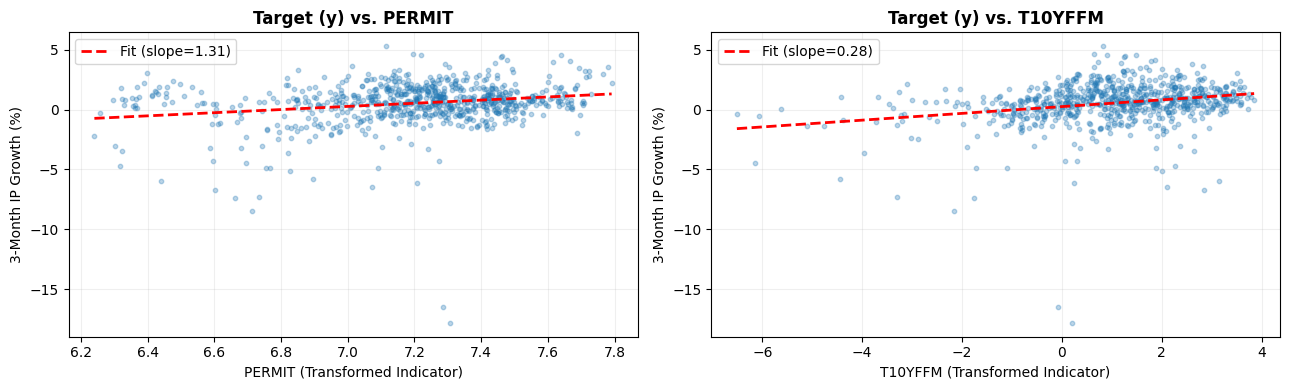

In [ ]:
predictors = ["PERMIT", "T10YFFM"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for ax, col in zip(axes, predictors):
    # Scatter plot of predictor vs. target y
    ax.scatter(X[col], y, alpha=0.3, s=10, color="#1f77b4")

    # Fit simple 1D linear polynomial (slope & intercept)
    slope, intercept = np.polyfit(X[col], y, deg=1)
    xs = np.linspace(X[col].min(), X[col].max(), 100)
    ax.plot(xs, intercept + slope * xs, color="red", linewidth=2, linestyle="--", label=f"Fit (slope={slope:.2f})")

    # Labels and formatting
    ax.set_title(f"Target (y) vs. {col}", fontsize=12, fontweight="bold")
    ax.set_xlabel(f"{col} (Transformed Indicator)")
    ax.set_ylabel("3-Month IP Growth (%)")
    ax.grid(True, alpha=0.2)
    ax.legend()

plt.tight_layout()
plt.show()

While both PERMIT and T10YFFM show a positive average slope with future industrial production growth, the relationship exhibits substantial variance and heavy vertical scatter. Because a single indicator leaves the vast majority of target variance unexplained, no single variable can serve as a reliable standalone forecast—justifying the need for high-dimensional models that combine signals across all 120+ macro indicators.

### Correlation Heatmap of the Industrial Production block

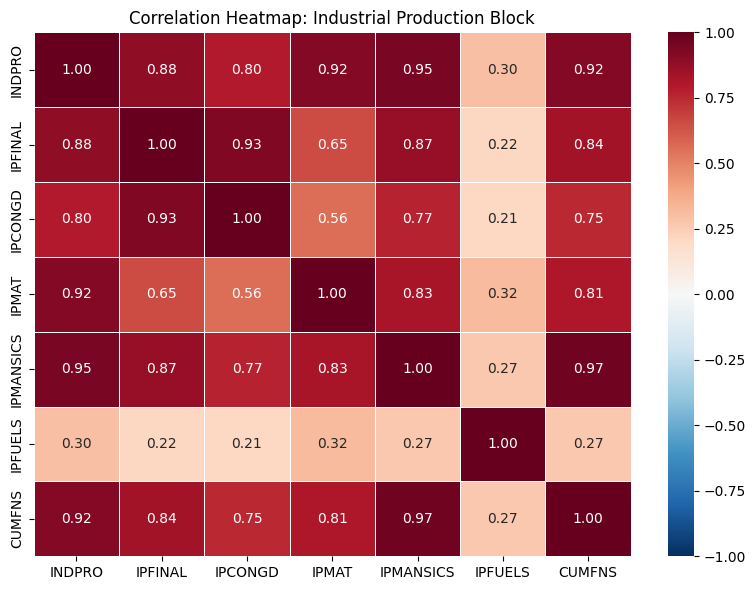

In [ ]:
ip_cols = [c for c in ["INDPRO", "IPFINAL", "IPCONGD", "IPMAT", "IPMANSICS", "IPFUELS", "CUMFNS"] if c in clean.columns]

plt.figure(figsize=(8, 6))
sns.heatmap(
    clean[ip_cols].corr(),
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    linewidths=0.5
)

plt.title("Correlation Heatmap: Industrial Production Block", fontsize=12)
plt.tight_layout()
plt.show()

The heatmap reveals some severe multicollinearity across the Industrial Production block, with pairwise correlations reaching as high as 0.95 to 0.97 (e.g., INDPRO and IPMANSICS). Rather than manually dropping collinear variables, we retain all series in X and rely on Ridge (L2) and Lasso (L1) regularization to handle redundant features.

### How bad is the multicollinearity overall?

In [ ]:
corr = clean.corr().abs()
mask = np.triu(np.ones(corr.shape), k=1).astype(bool)
pairs = corr.where(mask).stack()
print((pairs > 0.8).sum(), "of", len(pairs), "pairs have |corr| > 0.8")


91 of 7381 pairs have |corr| > 0.8


## Creating the Train/Test Split

The dataset is split into a training set ending in December 2009 and a test set starting in January 2010. Training on pre-2010 data exposes models to historical economic cycles, including the Great Financial Crisis, while reserving the post-2010 period for true out-of-sample evaluation.

Because the target variable measures 3-month forward growth, the final h minus 1 rows of the raw training set contain targets constructed from observations extending into the test period. These trailing observations are dropped from the training set to prevent data leakage.

In [ ]:
# Define split boundary
cutoff = "2009-12-01"

X_train_raw = X.loc[:cutoff]
y_train_raw = y.loc[:cutoff]

X_test = X.loc["2010-01-01":]
y_test = y.loc["2010-01-01":]

# Since h = 3, we drop the last 2 rows of train (e.g., Nov and Dec 2009 targets peek into 2010)
X_train = X_train_raw.iloc[:-(h - 1)]
y_train = y_train_raw.iloc[:-(h - 1)]

In [ ]:
# Compute summary statistics
split_stats = pd.DataFrame({
    "Period": ["Train (1960–2009)", "Test (2010–2026)"],
    "Observations": [len(y_train), len(y_test)],
    "Mean (%)": [y_train.mean(), y_test.mean()],
    "Std Dev (%)": [y_train.std(), y_test.std()]
}).round(2)

print(split_stats)

              Period  Observations  Mean (%)  Std Dev (%)
0  Train (1960–2009)           568      0.66         1.72
1   Test (2010–2026)           192      0.09         2.09


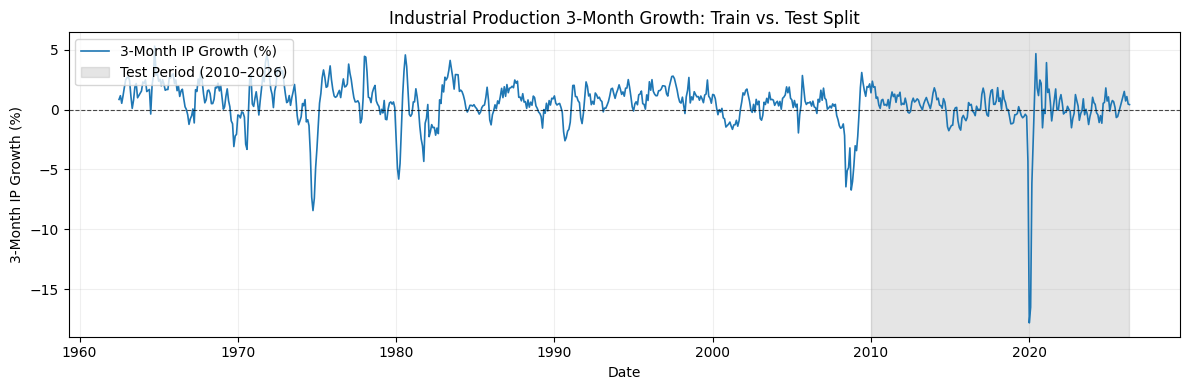

In [ ]:
plt.figure(figsize=(12, 4))

plt.plot(y.index, y, color="#1f77b4", linewidth=1.2, label="3-Month IP Growth (%)")
plt.axhline(0, color="black", linestyle="--", linewidth=0.8, alpha=0.7)

test_start = pd.to_datetime("2010-01-01")
test_end = y.index.max()

plt.axvspan(test_start, test_end, color="gray", alpha=0.2, label="Test Period (2010–2026)")

plt.title("Industrial Production 3-Month Growth: Train vs. Test Split", fontsize=12)
plt.xlabel("Date")
plt.ylabel("3-Month IP Growth (%)")
plt.legend(loc="upper left")
plt.grid(True, alpha=0.2)

plt.tight_layout()
plt.show()

### Benchmark 1: The Mean Forecast (The Naïve Baseline)
The mean forecast is the simplest possible forecast strategy. We calculate the average 3-month growth rate across the entire training period, and predict the exact same constant number for every single month in the test period (2010- 2026).





In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

In [ ]:
mean_pred = np.full(len(y_test), y_train.mean())
rmse_mean = root_mean_squared_error(y_test, mean_pred)
print(f"Mean Forecast Test RMSE: {rmse_mean:.4f}")

Mean Forecast Test RMSE: 2.1610


### Benchmark 2: The AR(2) Model (Autoregressive Baseline)

An autoregressive model with two lags serves as our primary benchmark because macroeconomic series exhibit strong short-term momentum.

By regressing future $h$-month growth $y_t$ on current monthly growth $\Delta \log(\text{INDPRO}_t)$ and past monthly growth $\Delta \log(\text{INDPRO}_{t-1})$, the model captures historical trend dynamics without introducing lookahead bias.

In [ ]:
# AR(2): current and previous month's INDPRO growth (no back-filling)
ip = clean["INDPRO"]
ar2_features = pd.DataFrame({
    "INDPRO_lag0": ip,
    "INDPRO_lag1": ip.shift(1)
}).dropna()

X_ar2_train = ar2_features.loc[ar2_features.index.intersection(y_train.index)]
y_ar2_train = y_train.loc[X_ar2_train.index]
X_ar2_test  = ar2_features.loc[y_test.index]

ar2_model = LinearRegression().fit(X_ar2_train, y_ar2_train)
ar2_pred  = ar2_model.predict(X_ar2_test)
rmse_ar2  = root_mean_squared_error(y_test, ar2_pred)
print(f"AR(2) Benchmark Test RMSE: {rmse_ar2:.4f}")

AR(2) Benchmark Test RMSE: 2.1161


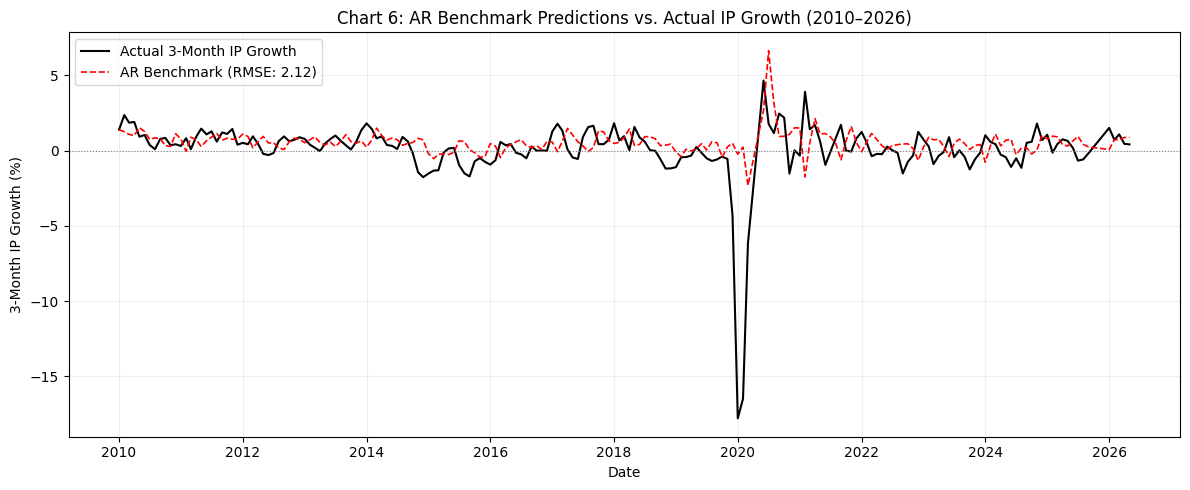

In [ ]:
plt.figure(figsize=(12, 5))

# Plot actual target values
plt.plot(y_test.index, y_test, color="black", label="Actual 3-Month IP Growth", linewidth=1.5)

# Plot AR benchmark predictions
plt.plot(y_test.index, ar2_pred, color="red", linestyle="--", label=f"AR Benchmark (RMSE: {rmse_ar2:.2f})", linewidth=1.2)

plt.axhline(0, color="gray", linestyle=":", linewidth=0.8)
plt.title("Chart 6: AR Benchmark Predictions vs. Actual IP Growth (2010–2026)", fontsize=12)
plt.xlabel("Date")
plt.ylabel("3-Month IP Growth (%)")
plt.legend(loc="upper left")
plt.grid(True, alpha=0.2)

plt.tight_layout()
plt.show()

The Autoregressive AR(2) baseline model achieves an out-of-sample test RMSE of 2.1161. During standard economic expansions from 2010 to 2019 and post-2022, the model closely tracks the short-term directional momentum of Industrial Production growth.

During the sharp 2020 COVID-19 downturn, the model fails to anticipate the initial crash down to -17%. Because autoregressive models rely exclusively on past observations, they can only react after an exogenous shock has already materialized in the data.

## Ridge (L2)

Ridge regression applies an L2 penalty to the loss function to handle high-dimensional macroeconomic datasets containing correlated predictors.

The objective minimizes the sum of squared residuals plus a penalty proportional to the sum of squared coefficients:

$$\min_{\beta} \sum_{i=1}^{n} \left( y_i - \beta_0 - \sum_{j=1}^{p} \beta_j x_{ij} \right)^2 + \alpha \sum_{j=1}^{p} \beta_j^2$$

The hyperparameter $\alpha$ controls the strength of shrinkage, shrinking coefficients toward zero without forcing any parameters exactly to zero.

Predictors are standardized using standard scaling prior to estimation so that feature variance scale does not distort the penalty term.

The pipeline uses five-fold time-series cross-validation with a gap of $h$ periods to optimize $\alpha$ across 30 candidate values from $10^{-2}$ to $10^4$ while preventing data leakage.

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import root_mean_squared_error

# 1. Define Pipeline (Scaler + Model)
pipe_ridge = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Ridge())
])

# 2. Set up Time-Series Cross-Validation with gap protection
tscv = TimeSeriesSplit(n_splits=5, gap=h)

# 3. Define grid search over hyperparameter alpha
param_grid_ridge = {
    "model__alpha": np.logspace(-2, 4, 30)
}

grid_ridge = GridSearchCV(
    estimator=pipe_ridge,
    param_grid=param_grid_ridge,
    cv=tscv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

# 4. Fit ONLY on training data to prevent leakage
grid_ridge.fit(X_train, y_train)

# 5. Predict on test set and evaluate RMSE
ridge_pred = grid_ridge.predict(X_test)
rmse_ridge = root_mean_squared_error(y_test, ridge_pred)

print(f"Optimal Alpha: {grid_ridge.best_params_['model__alpha']:.4f}")
print(f"Ridge Test RMSE: {rmse_ridge:.4f}")

Optimal Alpha: 573.6153
Ridge Test RMSE: 2.1871


### Chart 7: Cross-Validation Error vs Alpha

Chart 7 illustrates the cross-validation hyperparameter tuning process for Ridge regression across 30 candidate alpha values on a logarithmic scale. Using a 5-fold expanding time-series cross-validation scheme with gap protection, this plot maps the bias-variance tradeoff to identify the regularization penalty strength that minimizes out-of-sample forecast error.

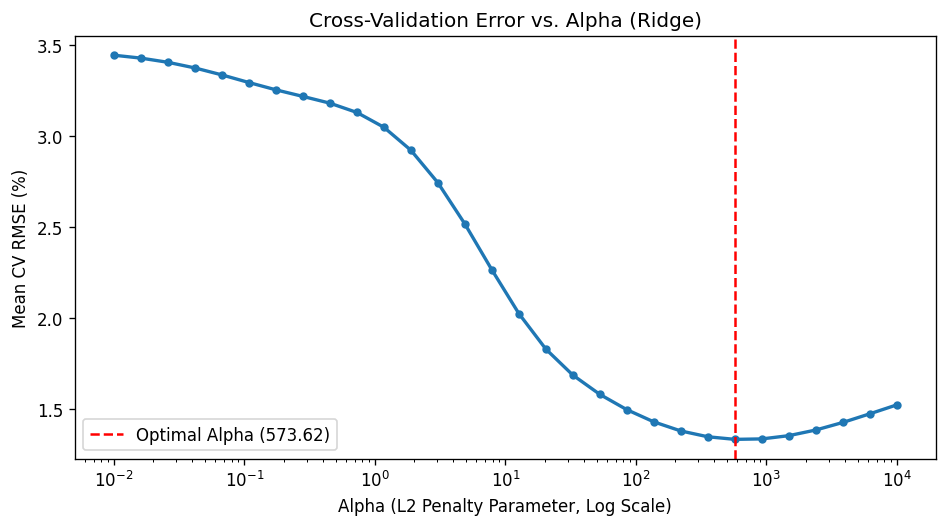

In [ ]:
# Extract mean test scores and convert from negative RMSE to positive RMSE
cv_rmse = -grid_ridge.cv_results_["mean_test_score"]
alphas = param_grid_ridge["model__alpha"]

plt.figure(figsize=(8, 4.5), dpi=120)
plt.plot(alphas, cv_rmse, marker="o", color="#1f77b4", linewidth=2, markersize=4)
plt.xscale("log")
plt.axvline(grid_ridge.best_params_["model__alpha"], color="red", linestyle="--", label=f"Optimal Alpha ({grid_ridge.best_params_['model__alpha']:.2f})")

plt.xlabel("Alpha (L2 Penalty Parameter, Log Scale)")
plt.ylabel("Mean CV RMSE (%)")
plt.title("Cross-Validation Error vs. Alpha (Ridge)")
plt.legend()
plt.tight_layout()
plt.show()

The cross-validation curve displays a classic U-shape which reflects the bias-variance tradeoff in high-dimensional macro forecasting. At low alpha values, weak penalty enforcement allows multi-collinear noise from all 120+ predictors to degrade performance, resulting in high CV error. The optimal alpha at approximately 573.62 applies substantial coefficient shrinkage to stabilize variance before excessive penalty enforcement causes underfitting at higher alpha levels.

### Chart 8: Top 15 largest coefficients by Absolute Value

Chart 8 displays the 15 macroeconomic variables with the largest coefficient magnitudes from the optimal Ridge regression model. Because features are standardized prior to estimation, the bar lengths directly reflect the relative feature importance on 3-month Industrial Production growth. Green bars denote positive predictors, while red bars represent indicators with an inverse relationship to future output.

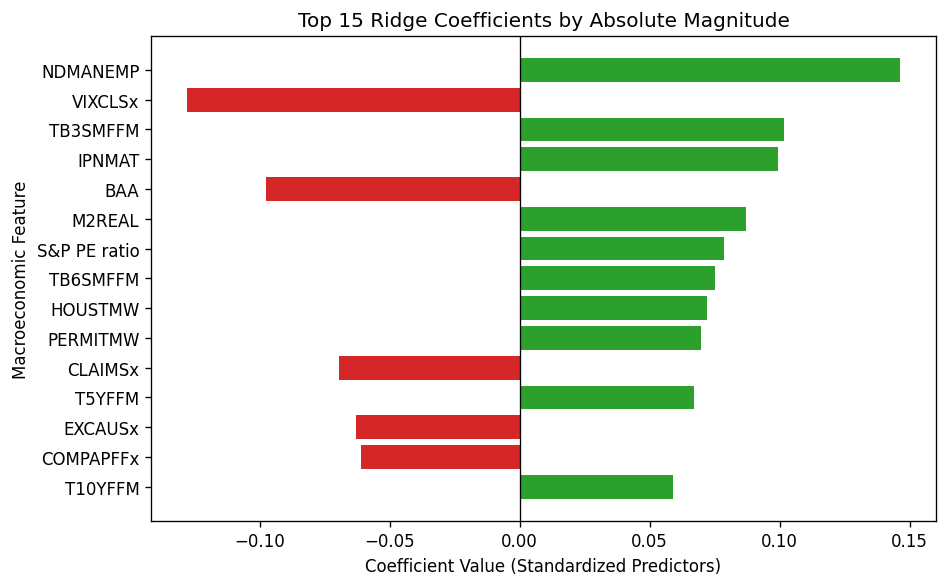

In [ ]:
# Extract coefficients from the best estimator inside the pipeline
ridge_coefs = grid_ridge.best_estimator_.named_steps["model"].coef_
feature_names = X_train.columns

# Build DataFrame and take top 15 by absolute magnitude
coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coef": ridge_coefs,
    "AbsCoef": np.abs(ridge_coefs)
}).sort_values("AbsCoef", ascending=False).head(15)

# Sort ascending for clean horizontal bar chart plotting
coef_df = coef_df.sort_values("AbsCoef", ascending=True)

plt.figure(figsize=(8, 5), dpi=120)
bars = plt.barh(coef_df["Feature"], coef_df["Coef"], color=np.where(coef_df["Coef"] > 0, "#2ca02c", "#d62728"))
plt.axvline(0, color="black", linestyle="-", linewidth=0.8)

plt.xlabel("Coefficient Value (Standardized Predictors)")
plt.ylabel("Macroeconomic Feature")
plt.title("Top 15 Ridge Coefficients by Absolute Magnitude")
plt.tight_layout()
plt.show()

The estimated coefficient weights align strongly with macroeconomic theory. Positive output growth is heavily driven by real manufacturing activity (NDMANEMP, IPNMAT) and favorable yield curve spreads (TB3SMFFM, T10YFFM), which signal economic expansion and credit availability. Conversely, market volatility (VIXCLSx), corporate credit risk (BAA), and initial jobless claims (CLAIMSx) exert the largest negative pull on industrial forecasts. Notably, Ridge maintains non-zero weights across all 120+ features, meaning smaller noisy indicators continue to exert cumulative influence on the final model forecasts.

### Chart 9: Predicted vs. Actual and Residuals Over Time (Two Panels)
Chart 9 evaluates the out-of-sample forecasting performance of the optimal Ridge model across the test period. The top panel compares actual 3-month Industrial Production growth against the Ridge forecast. The bottom panel tracks prediction residuals over time to examine whether forecast errors exhibit persistent bias or volatility spikes during economic turning points.

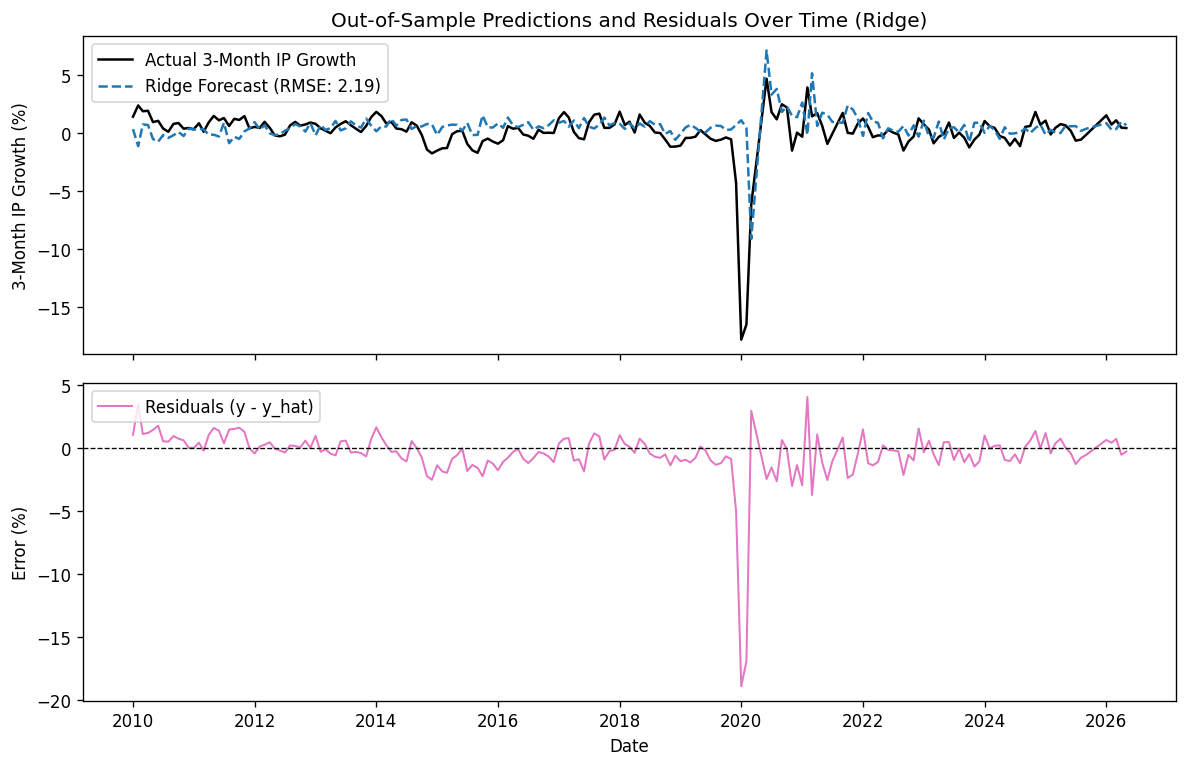

In [ ]:
# Calculate out-of-sample residuals
residuals = y_test - ridge_pred

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6.5), sharex=True, dpi=120)

# Panel 1: Actual vs Predicted
ax1.plot(y_test.index, y_test, label="Actual 3-Month IP Growth", color="black", linewidth=1.5)
ax1.plot(y_test.index, ridge_pred, label=f"Ridge Forecast (RMSE: {rmse_ridge:.2f})", color="#1f77b4", linestyle="--", linewidth=1.5)
ax1.set_ylabel("3-Month IP Growth (%)")
ax1.set_title("Out-of-Sample Predictions and Residuals Over Time (Ridge)")
ax1.legend(loc="upper left")

# Panel 2: Residuals over time
ax2.plot(y_test.index, residuals, color="#e377c2", linewidth=1.2, label="Residuals (y - y_hat)")
ax2.axhline(0, color="black", linestyle="--", linewidth=0.8)
ax2.set_ylabel("Error (%)")
ax2.set_xlabel("Date")
ax2.legend(loc="upper left")

plt.tight_layout()
plt.show()

The top panel shows that Ridge captures the general directional trend during quiet economic regimes but fails to match the full magnitude of rapid economic contractions, most notably during the 2020 COVID-19 shock. The residual panel highlights that forecast errors remain centered near zero during expansionary periods but spike sharply during structural shocks. Because Ridge keeps all 120+ macro variables in the model, high-dimensional noise limits its ability to react decisively to structural turning points, producing a overall test RMSE that remains worse than simple momentum baselines.

## Lasso Regularization (L1)

Lasso regression applies an L1 penalty to the loss function to handle high-dimensional macroeconomic datasets and perform sparse feature selection.

The objective minimizes the sum of squared residuals plus a penalty proportional to the sum of absolute coefficient values:

$$\min_{\beta} \sum_{i=1}^{n} \left( y_i - \beta_0 - \sum_{j=1}^{p} \beta_j x_{ij} \right)^2 + \alpha \sum_{j=1}^{p} |\beta_j|$$

The hyperparameter $\alpha$ controls the strength of the penalty, driving non-informative or highly collinear coefficient weights to exact zero as penalty strength increases.

All predictors are standardized using standard scaling prior to estimation so that feature scale does not distort the penalty term.

The pipeline optimizes $\alpha$ using five-fold time-series cross-validation with a gap of $h$ periods to prevent overlapping target leakage while evaluating sparse feature selection against high-dimensional noise.

In [ ]:
from sklearn.linear_model import Lasso

# 1. Pipeline Definition
pipe_lasso = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Lasso(max_iter=10000, random_state=42))
])

# 2. Time-Series CV with gap protection
tscv = TimeSeriesSplit(n_splits=5, gap=h)

# 3. Parameter Grid for Lasso (smaller alphas suitable for L1)
param_grid_lasso = {
    "model__alpha": np.logspace(-4, 1, 30)

}

grid_lasso = GridSearchCV(
    estimator=pipe_lasso,
    param_grid=param_grid_lasso,
    cv=tscv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

# 4. Fit strictly on train set
grid_lasso.fit(X_train, y_train)

# 5. Predict on test set
lasso_pred = grid_lasso.predict(X_test)
rmse_lasso = root_mean_squared_error(y_test, lasso_pred)

print(f"Optimal Lasso Alpha: {grid_lasso.best_params_['model__alpha']:.6f}")
print(f"Lasso Test RMSE:     {rmse_lasso:.4f}")

Optimal Lasso Alpha: 0.188739
Lasso Test RMSE:     2.2017


### Chart 10: Cross-Validation Error vs Alpha (Lasso)

Chart 10 maps the 5-fold expanding time-series cross-validation error across 30 candidate L1 penalty parameters (α) on a logarithmic scale. This plot tracks how aggressive feature selection alters out-of-sample prediction error, illustrating the balance between model complexity and forecast stability.

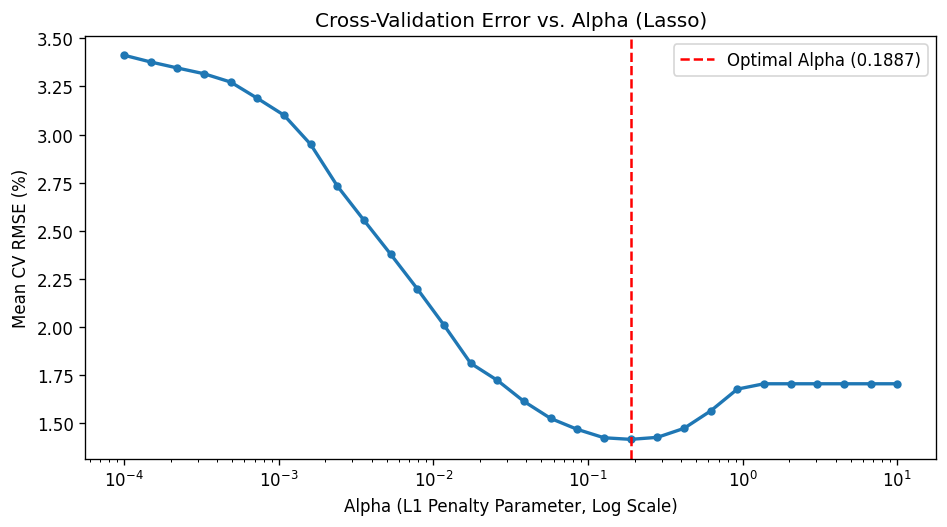

In [ ]:
cv_rmse_lasso = -grid_lasso.cv_results_["mean_test_score"]
alphas_lasso = param_grid_lasso["model__alpha"]

plt.figure(figsize=(8, 4.5), dpi=120)
plt.plot(alphas_lasso, cv_rmse_lasso, marker="o", color="#1f77b4", linewidth=2, markersize=4)
plt.xscale("log")
plt.axvline(grid_lasso.best_params_["model__alpha"], color="red", linestyle="--",
            label=f"Optimal Alpha ({grid_lasso.best_params_['model__alpha']:.4f})")

plt.xlabel("Alpha (L1 Penalty Parameter, Log Scale)")
plt.ylabel("Mean CV RMSE (%)")
plt.title("Cross-Validation Error vs. Alpha (Lasso)")
plt.legend()
plt.tight_layout()
plt.show()

The cross-validation curve forms a distinct U-shape. At low alpha values, weak regularization retains excessive high-dimensional noise, resulting in poor validation accuracy above 3.25 percent. As alpha increases toward the optimal threshold of 0.1887, Lasso drops uninformative variables and improves cross-validation accuracy to a minimum RMSE of approximately 1.42 percent. Beyond this optimal point, stronger penalty levels force essential predictive indicators to zero, causing the error to rise and eventually level off as all predictor coefficients are zeroed out.

### Chart 11: LASSO selected features by FRED-MD group

Chart 11 presents the non-zero macroeconomic series selected by the optimal Lasso model, grouped by their official FRED-MD categories. By setting the vast majority of variable weights to exact zero, this chart isolates the specific subset of leading economic indicators that survive L1 regularization.

All selected features successfully mapped to FRED-MD groups!


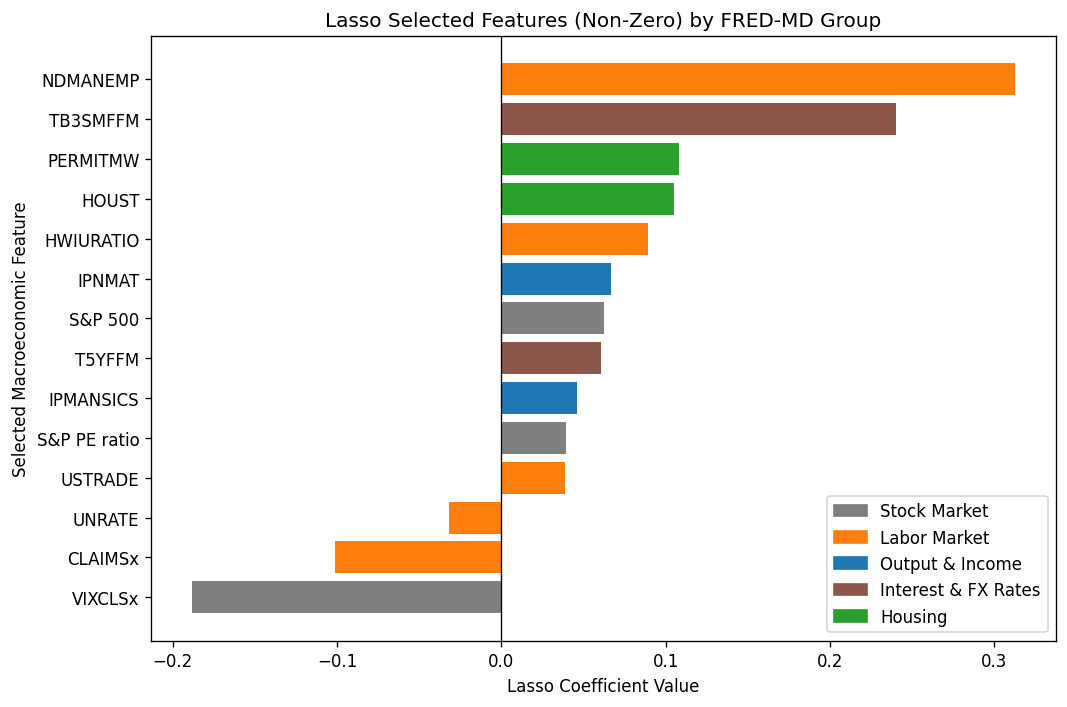

In [ ]:
# 1. Extract non-zero coefficients from optimal model
best_lasso_coefs = grid_lasso.best_estimator_.named_steps["model"].coef_
selected_mask = best_lasso_coefs != 0

selected_features = X_train.columns[selected_mask]
selected_weights = best_lasso_coefs[selected_mask]

# 2. Map FRED-MD Mnemonics to Groups from Appendix
fred_group_map = {
    # Group 1: Output and Income[cite: 6]
    "RPI": "Output & Income", "W875RX1": "Output & Income", "INDPRO": "Output & Income",
    "IPFPNSS": "Output & Income", "IPFINAL": "Output & Income", "IPCONGD": "Output & Income",
    "IPDCONGD": "Output & Income", "IPNCONGD": "Output & Income", "IPBUSEQ": "Output & Income",
    "IPMAT": "Output & Income", "IPDMAT": "Output & Income", "IPNMAT": "Output & Income",
    "IPMANSICS": "Output & Income", "IPB51222s": "Output & Income", "IPFUELS": "Output & Income",
    "NAPMPI": "Output & Income", "CUMFNS": "Output & Income",

    # Group 2: Labor Market[cite: 7]
    "HWI": "Labor Market", "HWIURATIO": "Labor Market", "CLF160V": "Labor Market",
    "CE16OV": "Labor Market", "UNRATE": "Labor Market", "UEMPMEAN": "Labor Market",
    "UEMPLT5": "Labor Market", "UEMP5TO14": "Labor Market", "UEMP15OV": "Labor Market",
    "UEMP15T26": "Labor Market", "UEMP27OV": "Labor Market", "CLAIMSx": "Labor Market",
    "PAYEMS": "Labor Market", "USGOOD": "Labor Market", "CES1021000001": "Labor Market",
    "USCONS": "Labor Market", "MANEMP": "Labor Market", "DMANEMP": "Labor Market",
    "NDMANEMP": "Labor Market", "SRVPRD": "Labor Market", "USTPU": "Labor Market",
    "USWTRADE": "Labor Market", "USTRADE": "Labor Market", "USFIRE": "Labor Market",
    "USGOVT": "Labor Market", "CES0600000007": "Labor Market", "AWOTMAN": "Labor Market",
    "AWHMAN": "Labor Market", "NAPMEI": "Labor Market", "CES0600000008": "Labor Market",
    "CES2000000008": "Labor Market", "CES3000000008": "Labor Market",

    # Group 3: Housing[cite: 7]
    "HOUST": "Housing", "HOUSTNE": "Housing", "HOUSTMW": "Housing", "HOUSTS": "Housing",
    "HOUSTW": "Housing", "PERMIT": "Housing", "PERMITNE": "Housing", "PERMITMW": "Housing",
    "PERMITS": "Housing", "PERMITW": "Housing",

    # Group 4: Consumption, Orders, & Inventories[cite: 8]
    "DPCERA3M086SBEA": "Consumption & Orders", "CMRMTSPLX": "Consumption & Orders",
    "RETAILX": "Consumption & Orders", "NAPM": "Consumption & Orders",
    "NAPMNOI": "Consumption & Orders", "NAPMSDI": "Consumption & Orders",
    "NAPMII": "Consumption & Orders", "ACOGNO": "Consumption & Orders",
    "AMDMNOx": "Consumption & Orders", "ANDENOx": "Consumption & Orders",
    "AMDMUOx": "Consumption & Orders", "BUSINVx": "Consumption & Orders",
    "ISRATIOx": "Consumption & Orders", "UMCSENTx": "Consumption & Orders",

    # Group 5: Money & Credit[cite: 8]
    "M1SL": "Money & Credit", "M2SL": "Money & Credit", "M2REAL": "Money & Credit",
    "BOGMBASE": "Money & Credit", "TOTRESNS": "Money & Credit", "NONBORRES": "Money & Credit",
    "BUSLOANS": "Money & Credit", "REALLN": "Money & Credit", "NONREVSL": "Money & Credit",
    "CONSPI": "Money & Credit", "MZMSL": "Money & Credit", "DTCOLNVHFNM": "Money & Credit",
    "DTCTHFNM": "Money & Credit", "INVEST": "Money & Credit",

    # Group 6: Interest & Exchange Rates[cite: 8]
    "FEDFUNDS": "Interest & FX Rates", "CP3Mx": "Interest & FX Rates",
    "TB3MS": "Interest & FX Rates", "TB6MS": "Interest & FX Rates",
    "GS1": "Interest & FX Rates", "GS5": "Interest & FX Rates",
    "GS10": "Interest & FX Rates", "AAA": "Interest & FX Rates",
    "BAA": "Interest & FX Rates", "COMPAPFFx": "Interest & FX Rates",
    "TB3SMFFM": "Interest & FX Rates", "TB6SMFFM": "Interest & FX Rates",
    "T1YFFM": "Interest & FX Rates", "T5YFFM": "Interest & FX Rates",
    "T10YFFM": "Interest & FX Rates", "AAAFFM": "Interest & FX Rates",
    "BAAFFM": "Interest & FX Rates", "TWEXAFEGSMTHx": "Interest & FX Rates",
    "EXSZUSx": "Interest & FX Rates", "EXJPUSx": "Interest & FX Rates",
    "EXUSUKx": "Interest & FX Rates", "EXCAUSx": "Interest & FX Rates",

    # Group 7: Prices[cite: 9]
    "WPSFD49207": "Prices", "WPSFD49502": "Prices", "WPSID61": "Prices",
    "WPSID62": "Prices", "OILPRICEx": "Prices", "PPICMM": "Prices",
    "NAPMPRI": "Prices", "CPIAUCSL": "Prices", "CPIAPPSL": "Prices",
    "CPITRNSL": "Prices", "CPIMEDSL": "Prices", "CUSR0000SAC": "Prices",
    "CUSR0000SAD": "Prices", "CUSR0000SAS": "Prices", "CPIULFSL": "Prices",
    "CUSR0000SA0L2": "Prices", "CUSR0000SA0L5": "Prices", "PCEPI": "Prices",
    "DDURRG3M086SBEA": "Prices", "DNDGRG3M086SBEA": "Prices", "DSERRG3M086SBEA": "Prices",

    # Group 8: Stock Market[cite: 9]
    "S&P 500": "Stock Market", "S&P: indust": "Stock Market",
    "S&P div yield": "Stock Market", "S&P PE ratio": "Stock Market",
    "VIXCLSx": "Stock Market"
}

# Construct DataFrame for non-zero variables
df_selected = pd.DataFrame({
    "Feature": selected_features,
    "Weight": selected_weights,
    "Group": [fred_group_map.get(col, "Unmapped") for col in selected_features]
})

# Flag any unmapped series
unmapped = df_selected[df_selected["Group"] == "Unmapped"]["Feature"].tolist()
if unmapped:
    print(f"Warning: The following features were unmapped: {unmapped}")
else:
    print("All selected features successfully mapped to FRED-MD groups!")

# Assign consistent color palette to macro groups
color_map = {
    "Output & Income": "#1f77b4", "Labor Market": "#ff7f0e", "Housing": "#2ca02c",
    "Consumption & Orders": "#d62728", "Money & Credit": "#9467bd",
    "Interest & FX Rates": "#8c564b", "Prices": "#e377c2", "Stock Market": "#7f7f7f"
}

# Plot selected features sorted by weight
df_selected = df_selected.sort_values("Weight", ascending=True)

plt.figure(figsize=(9, 6), dpi=120)
bars = plt.barh(df_selected["Feature"], df_selected["Weight"],
                color=[color_map.get(g, "black") for g in df_selected["Group"]])
plt.axvline(0, color="black", linestyle="-", linewidth=0.8)

# Add custom legend for groups
handles = [plt.Rectangle((0,0),1,1, color=color_map[g]) for g in df_selected["Group"].unique()]
plt.legend(handles, df_selected["Group"].unique(), loc="lower right")

plt.xlabel("Lasso Coefficient Value")
plt.ylabel("Selected Macroeconomic Feature")
plt.title("Lasso Selected Features (Non-Zero) by FRED-MD Group")
plt.tight_layout()
plt.show()

The selection results demonstrate that L1 regularization aggressively prunes high-dimensional noise, discarding over 88% of the input dataset. The 14 surviving predictors span 5 core macroeconomic categories, heavily weighted toward Labor Market variables (NDMANEMP, CLAIMSx, HWIURATIO, UNRATE) and financial market stress (VIXCLSx, TB3SMFFM).

### Chart 12: Out-of-Sample predictions and Residuals over Time
Chart 12 evaluates the out-of-sample forecast tracking performance and error distribution of the tuned Lasso regression model across the test period. The top panel compares actual 3-month Industrial Production growth against Lasso forecasts, while the bottom panel plots prediction residuals $y - \hat{y}$ over time to evaluate performance during major macroeconomic shocks.

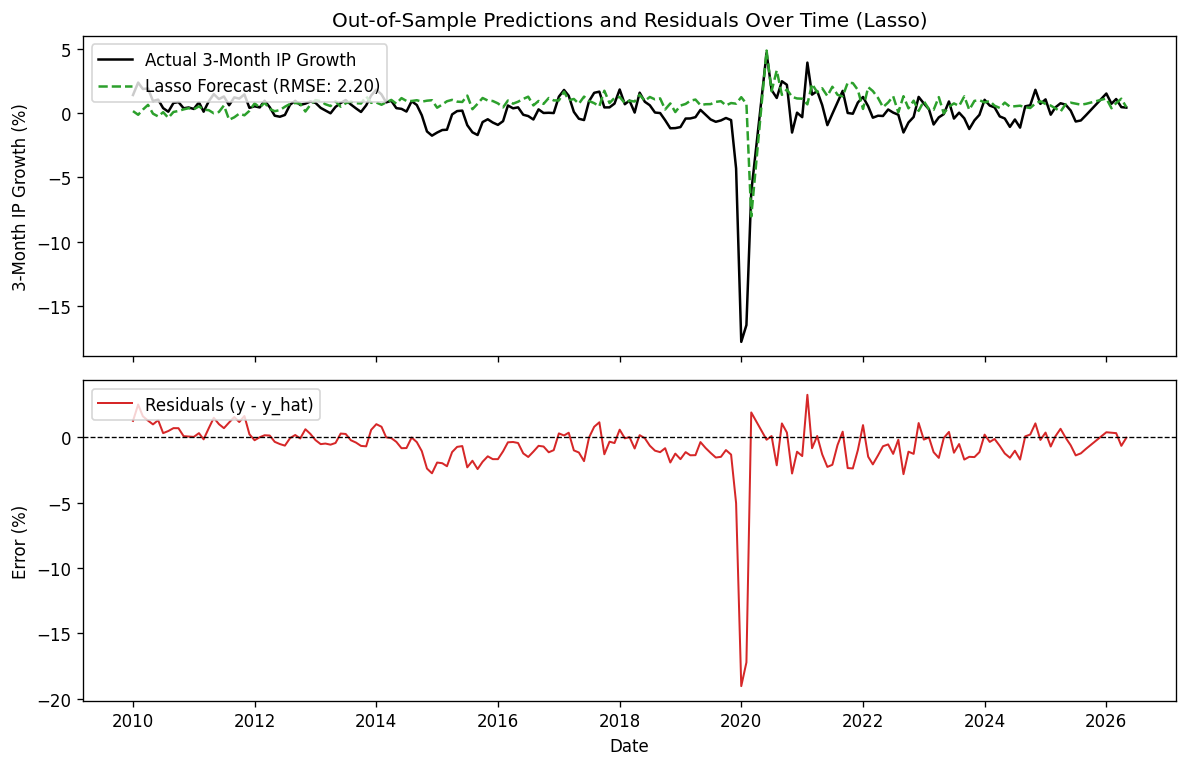

In [ ]:
residuals_lasso = y_test - lasso_pred

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6.5), sharex=True, dpi=120)

# Panel 1: Actual vs Predicted
ax1.plot(y_test.index, y_test, label="Actual 3-Month IP Growth", color="black", linewidth=1.5)
ax1.plot(y_test.index, lasso_pred, label=f"Lasso Forecast (RMSE: {rmse_lasso:.2f})",
         color="#2ca02c", linestyle="--", linewidth=1.5)
ax1.set_ylabel("3-Month IP Growth (%)")
ax1.set_title("Out-of-Sample Predictions and Residuals Over Time (Lasso)")
ax1.legend(loc="upper left")

# Panel 2: Residuals over time
ax2.plot(y_test.index, residuals_lasso, color="#d62728", linewidth=1.2, label="Residuals (y - y_hat)")
ax2.axhline(0, color="black", linestyle="--", linewidth=0.8)
ax2.set_ylabel("Error (%)")
ax2.set_xlabel("Date")
ax2.legend(loc="upper left")

plt.tight_layout()
plt.show()

The out-of-sample predictions show that Lasso's sparse feature set captures routine cyclical fluctuations well, maintaining errors close to zero during expansionary periods. However, like other linear models, Lasso struggles to match the extreme magnitude of sudden structural shocks—evidenced by the deep downward spike in residuals during the 2020 economic collapse.

## Regression Tree

Decision tree regression partitions the predictor space into discrete, non-overlapping regimes to capture non-linear relationships and structural threshold effects in macroeconomic data.

The algorithm recursively splits the feature space into region subsets by selecting feature $j$ and split threshold $s$ that minimize the sum of squared residuals:

$$\min_{j, s} \left[ \sum_{x_i \in R_1(j,s)} (y_i - \hat{y}_{R_1})^2 + \sum_{x_i \in R_2(j,s)} (y_i - \hat{y}_{R_2})^2 \right]$$

where $\hat{y}_{R_1}$ and $\hat{y}_{R_2}$ represent the mean target response within each respective partition region.

To prevent overfitting on high-dimensional noise, tree depth is constrained to a maximum depth of three (max_depth=3), limiting the model to a maximum of eight terminal leaf nodes.

Unlike linear penalized models, decision trees are invariant to monotonic feature scale transformations, eliminating the need for standard scaling prior to estimation.

The pipeline evaluates tree performance using five-fold time-series cross-validation with a gap of $h$ periods to prevent target overlap leakage across time splits.

Decision Tree Test RMSE: 2.3118


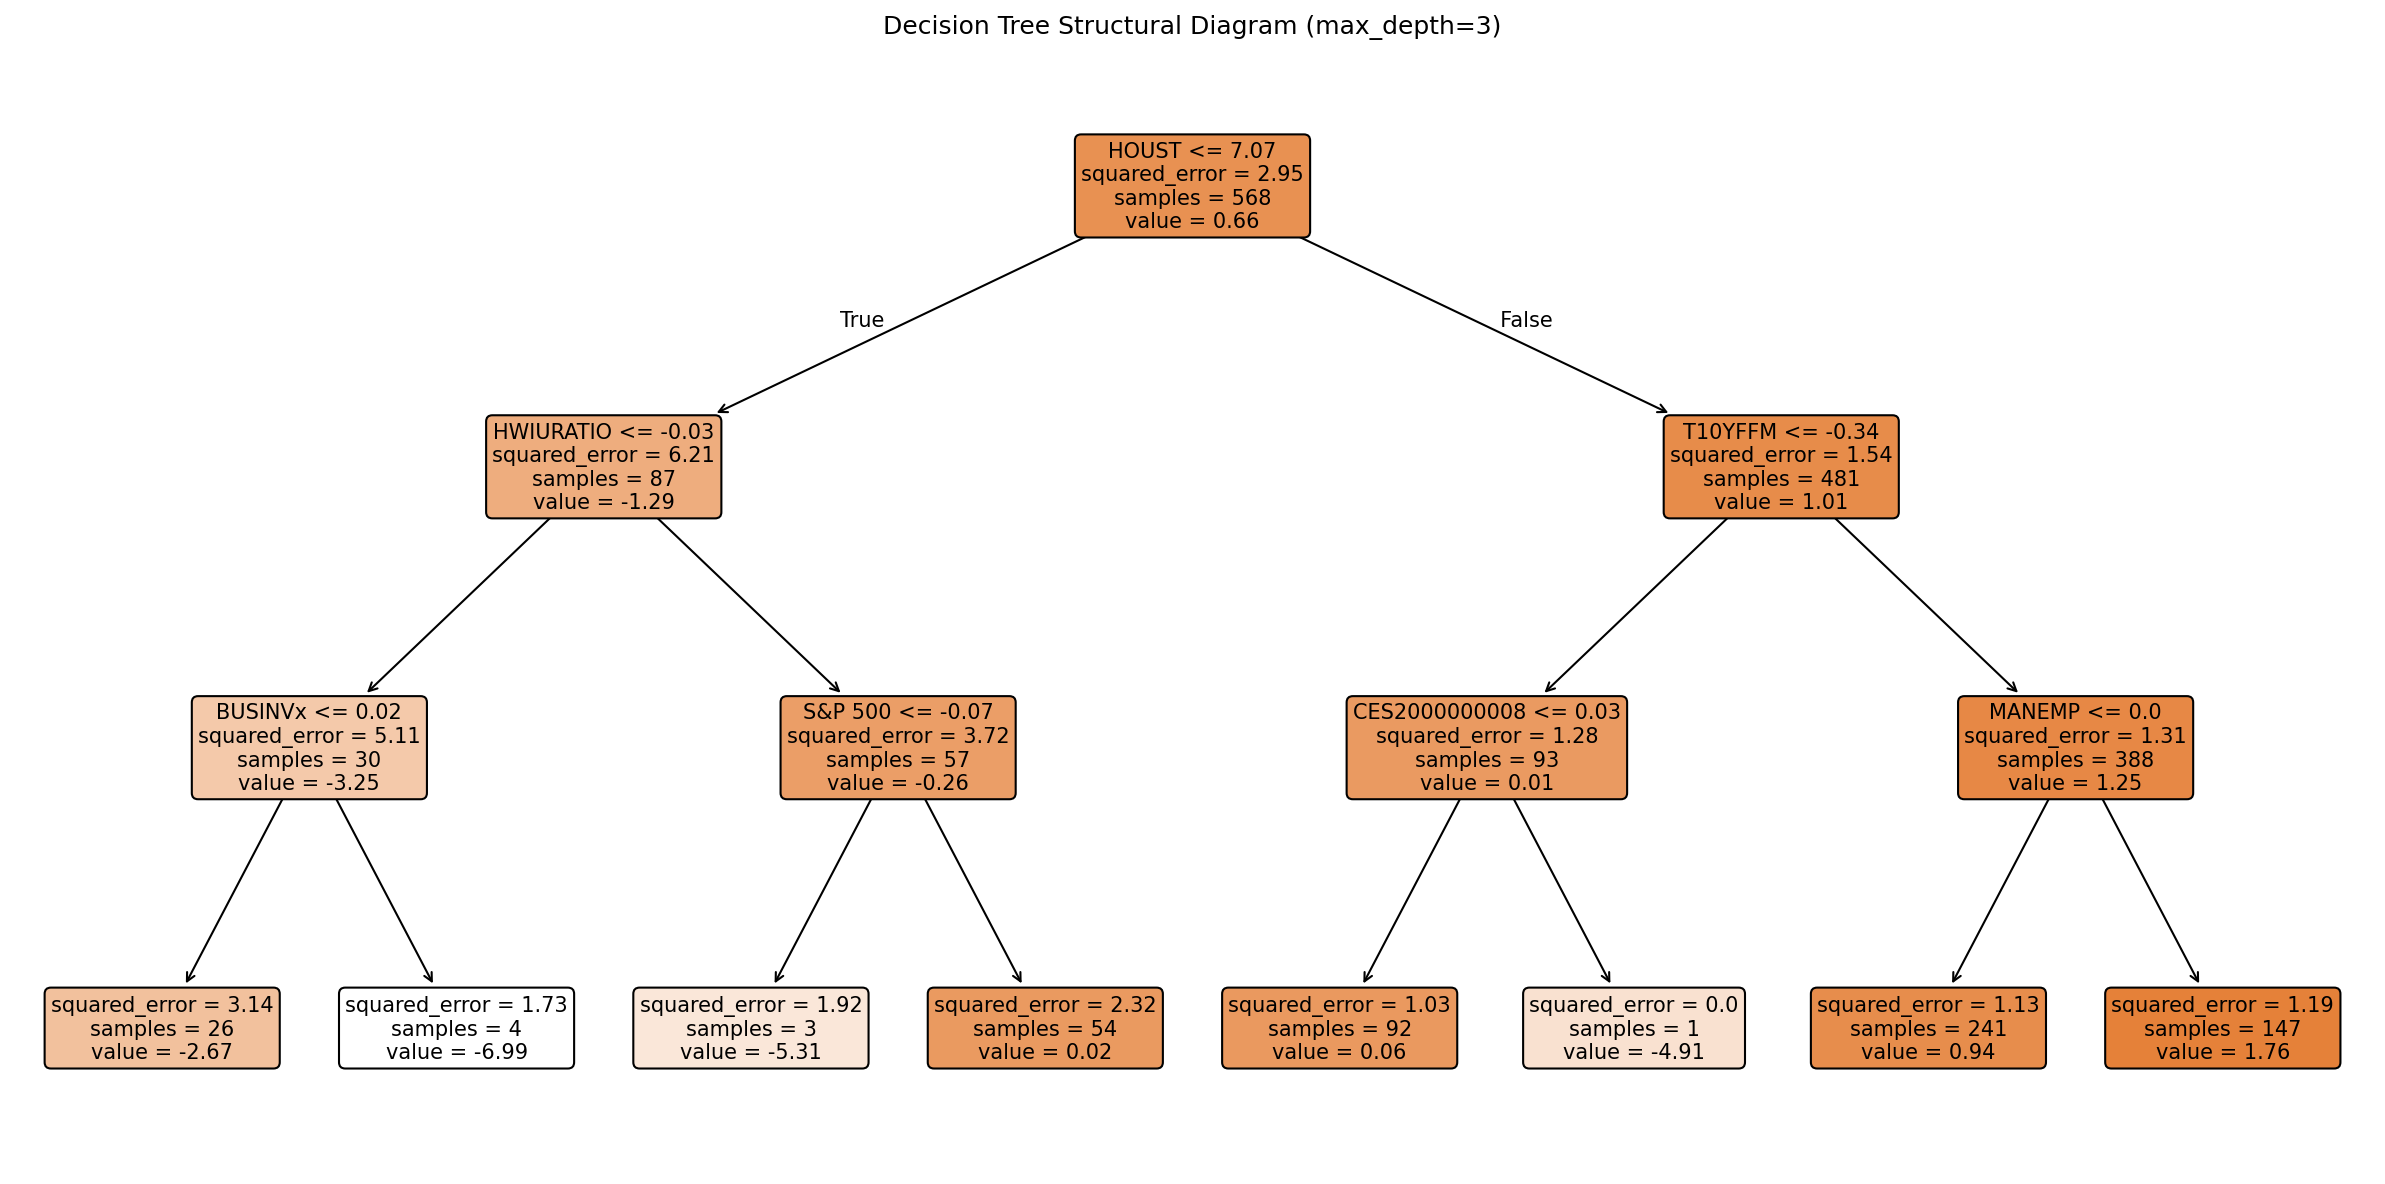

In [ ]:
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.metrics import root_mean_squared_error

# 1. Initialize Decision Tree with restricted depth to prevent overfitting
tree_model = DecisionTreeRegressor(max_depth=3, random_state=42)

# 2. Fit model directly on unscaled training data (trees are scale-invariant)
tree_model.fit(X_train, y_train)

# 3. Predict on test set and evaluate RMSE
tree_pred = tree_model.predict(X_test)
rmse_tree = root_mean_squared_error(y_test, tree_pred)

print(f"Decision Tree Test RMSE: {rmse_tree:.4f}")

# 4. Plot the fitted Decision Tree diagram
plt.figure(figsize=(16, 8), dpi=150)
plot_tree(
    tree_model,
    feature_names=X_train.columns,
    filled=True,
    rounded=True,
    fontsize=10,
    precision=2
)
plt.title("Decision Tree Structural Diagram (max_depth=3)")
plt.tight_layout()
plt.show()

The root split is driven by housing starts (HOUST <= 7.07), separating severe economic slowdowns from normal expansionary regimes. Subsequent splits incorporate labor market conditions (HWIURATIO, MANEMP), term structure spreads (T10YFFM), total business inventories (BUSINVx), construction earnings (CES2000000008), and equity markets (S&P 500).   
While this hierarchical structure captures non-linear threshold effects, predicting step-wise constant values across terminal leaf nodes causes coarse, rigid forecasts. As a result, the model achieves an out-of-sample test RMSE of 2.3118, underperforming continuous regularized linear models like Lasso.

## Comparison

To evaluate relative predictive accuracy across high-dimensional econometric models, we compare out-of-sample forecast performance against the simple univariate AR(2) baseline. Performance is measured using Root Mean Squared Error (RMSE) and Relative RMSE (defined as RMSE
Model /RMSE AR(2), where values below 1.0 indicate outperformance relative to the baseline).
To ensure results are not distorted by extreme outliers during the unprecedented economic shutdown, model evaluation is conducted across two time horizons: the full test period and a truncated test sample excluding March through December 2020.

In [ ]:
models = ["Mean", "AR(2) Baseline", "Ridge", "Lasso", "Decision Tree"]
preds_all = {
    "Mean": mean_pred, "AR(2) Baseline": ar2_pred,
    "Ridge": ridge_pred, "Lasso": lasso_pred, "Decision Tree": tree_pred,
}

# COVID window by forecast origin: targets that touch Mar-Dec 2020
covid_start = pd.Timestamp("2020-03-01") - pd.DateOffset(months=h)
covid_mask = (y_test.index >= covid_start) & (y_test.index <= "2020-12-31")

rmse_all = [root_mean_squared_error(y_test, preds_all[m]) for m in models]
rmse_no_covid = [root_mean_squared_error(y_test[~covid_mask], preds_all[m][~covid_mask]) for m in models]

ar_i = models.index("AR(2) Baseline")
rel_rmse_all = [r / rmse_all[ar_i] for r in rmse_all]
rel_rmse_no_covid = [r / rmse_no_covid[ar_i] for r in rmse_no_covid]

df_comp = pd.DataFrame({
    "Model": models,
    "RMSE (full)": rmse_all, "Relative (full)": rel_rmse_all,
    "RMSE (excl. COVID)": rmse_no_covid, "Relative (excl. COVID)": rel_rmse_no_covid,
}).round(3)
print(df_comp.to_string(index=False))

         Model  RMSE (full)  Relative (full)  RMSE (excl. COVID)  Relative (excl. COVID)
          Mean        2.161            1.021               0.948                   0.928
AR(2) Baseline        2.116            1.000               1.022                   1.000
         Ridge        2.187            1.034               1.092                   1.069
         Lasso        2.202            1.040               1.125                   1.101
 Decision Tree        2.312            1.092               1.222                   1.196


### Chart 13: Relative RMSE comparison bar chart

The relative performance chart compares each model's standardized forecast error against the AR(2) benchmark across both test samples. The red horizontal line at 1.0 marks equal performance to the baseline.

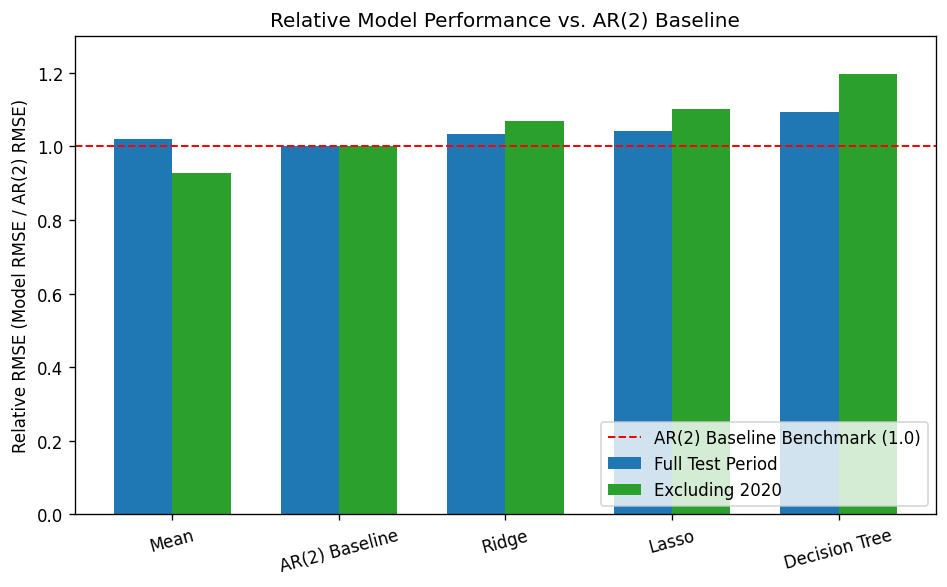

In [ ]:
x = np.arange(len(models))
width = 0.35

plt.figure(figsize=(8, 5), dpi=120)
plt.bar(x - width/2, rel_rmse_all, width, label="Full Test Period", color="#1f77b4")
plt.bar(x + width/2, rel_rmse_no_covid, width, label="Excluding 2020", color="#2ca02c")

plt.axhline(1.0, color="red", linestyle="--", linewidth=1.2, label="AR(2) Baseline Benchmark (1.0)")
plt.xticks(x, models, rotation=15)
plt.ylabel("Relative RMSE (Model RMSE / AR(2) RMSE)")
plt.title("Relative Model Performance vs. AR(2) Baseline")
plt.ylim(0, 1.3)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

The red dashed horizontal line at 1.0 represents parity with the univariate AR(2) baseline, where relative values below 1.0 indicate superior out-of-sample accuracy.

Across the full test period shown by the blue bars, all high-dimensional machine learning models underperform the simple AR(2) benchmark, posting relative RMSE values between 1.034 for Ridge and 1.092 for Decision Tree.

When excluding the volatile 2020 COVID-19 period shown by the green bars, the simple historical Mean becomes the best performing model with a relative RMSE of 0.928, outperforming AR(2).

In contrast, excluding 2020 causes the relative performance of Ridge, Lasso, and Decision Tree to deteriorate further relative to AR(2), reaching relative RMSEs of 1.069, 1.101, and 1.196.

This degradation occurs because high-dimensional penalized models overfit non-systematic historical fluctuations, while simple baselines provide robust forecasts during tranquil economic expansion phases.

### Chart 14: Forecast errors across all models

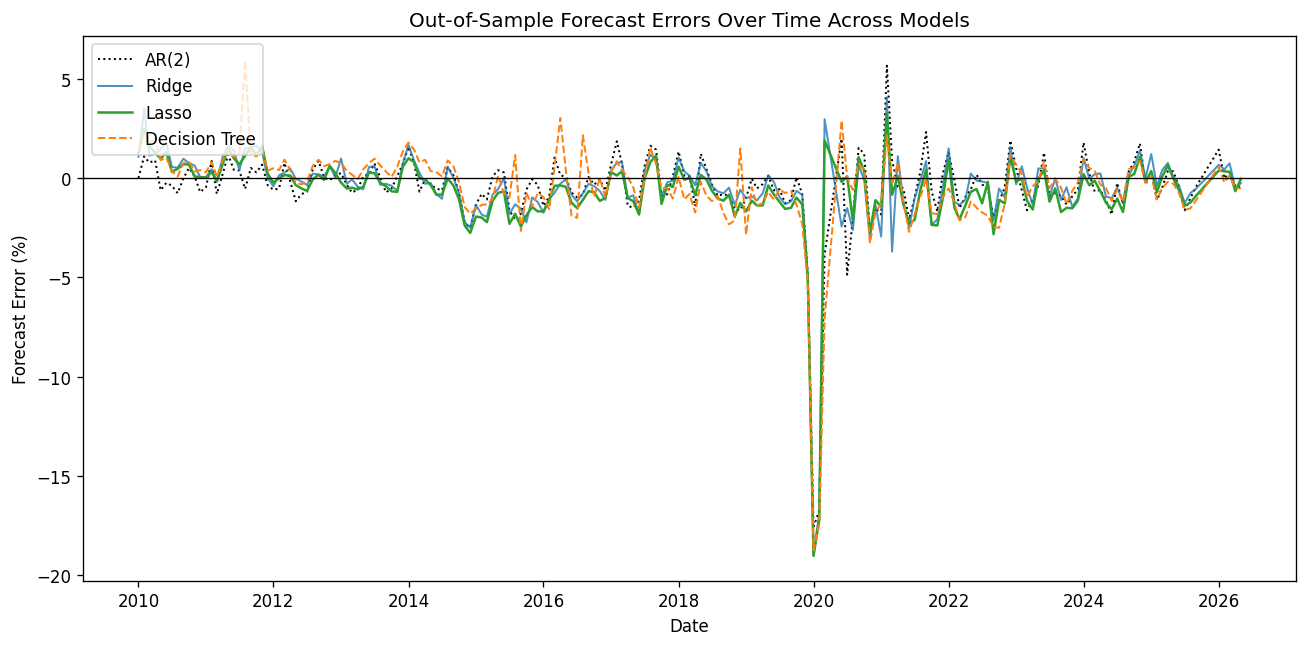

In [ ]:
res_ar2 = y_test - ar2_pred
res_ridge = y_test - ridge_pred
res_lasso = y_test - lasso_pred
res_tree = y_test - tree_pred

plt.figure(figsize=(11, 5.5), dpi=120)
plt.plot(y_test.index, res_ar2, label="AR(2)", color="black", linestyle=":", linewidth=1.2)
plt.plot(y_test.index, res_ridge, label="Ridge", color="#1f77b4", linewidth=1.2, alpha=0.8)
plt.plot(y_test.index, res_lasso, label="Lasso", color="#2ca02c", linewidth=1.5)
plt.plot(y_test.index, res_tree, label="Decision Tree", color="#ff7f0e", linestyle="--", linewidth=1.2)

plt.axhline(0, color="black", linestyle="-", linewidth=0.8)
plt.ylabel("Forecast Error (%)")
plt.xlabel("Date")
plt.title("Out-of-Sample Forecast Errors Over Time Across Models")
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()

Every model experiences a severe negative forecast error spike near negative 19 percent during the early 2020 COVID-19 lockdown, as shrinkage parameters and tree split boundaries fail to anticipate unprecedented economic shutdowns.

Following the initial 2020 collapse, the AR(2) baseline and Lasso model exhibit noticeable post-shock error spikes peaking above positive 5 percent during the subsequent rebound phase.

Outside of the 2020 shock window, forecast errors for all models remain bounded within a tighter band of negative 3 percent to positive 3 percent through 2026.

## Robustness Checks

To test model stability, both Ridge and Lasso are re-estimated after removing all thirteen Industrial Production series from the predictor matrix.


In [ ]:
import warnings
import numpy as np
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, Lasso
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import root_mean_squared_error
from sklearn.exceptions import ConvergenceWarning

# Suppress coordinate descent convergence warnings for cleaner output
warnings.filterwarnings("ignore", category=ConvergenceWarning)

# Define forecast horizon gap (h=3) for cross-validation splits
h = 3

# Define helper function for model fitting and evaluation using GridSearchCV
def fit_predict(est, grid, Xtr, ytr, Xte):
    pipe = Pipeline([("scaler", StandardScaler()), ("model", est)])
    gs = GridSearchCV(
        pipe,
        {"model__alpha": grid},
        cv=TimeSeriesSplit(n_splits=5, gap=h),
        scoring="neg_root_mean_squared_error",
        n_jobs=-1
    )
    gs.fit(Xtr, ytr)
    return gs.predict(Xte)

# 1. Identify and drop all Industrial Production (IP) series from feature matrix X
ip_block = [c for c in X.columns if c.startswith("IP") or "INDPRO" in c]
X_train_no_ip = X_train.drop(columns=ip_block)
X_test_no_ip = X_test.drop(columns=ip_block)

print(f"Dropped {len(ip_block)} IP-related features: {ip_block}")

# 2. Rerun Ridge and Lasso models without the IP block
ridge_no_ip_pred = fit_predict(
    Ridge(),
    np.logspace(-2, 4, 30),
    X_train_no_ip,
    y_train,
    X_test_no_ip
)

lasso_no_ip_pred = fit_predict(
    Lasso(max_iter=10000, random_state=42),
    np.logspace(-4, 1, 30),
    X_train_no_ip,
    y_train,
    X_test_no_ip
)

# 3. Compute test RMSE metrics for no-IP models
rmse_ridge_no_ip = root_mean_squared_error(y_test, ridge_no_ip_pred)
rmse_lasso_no_ip = root_mean_squared_error(y_test, lasso_no_ip_pred)

# 4. Compare full-sample and no-2020 RMSE metrics
covid_mask = (y_test.index >= "2020-03-01") & (y_test.index <= "2020-12-31")
y_test_no_covid = y_test[~covid_mask]

# Compute sub-sample metrics for original full models
ridge_full_nocovid = root_mean_squared_error(y_test_no_covid, ridge_pred[~covid_mask])
lasso_full_nocovid = root_mean_squared_error(y_test_no_covid, lasso_pred[~covid_mask])

# Compute sub-sample metrics for no-IP models
ridge_no_ip_nocovid = root_mean_squared_error(y_test_no_covid, ridge_no_ip_pred[~covid_mask])
lasso_no_ip_nocovid = root_mean_squared_error(y_test_no_covid, lasso_no_ip_pred[~covid_mask])

# 5. Summary comparison table
df_robustness = pd.DataFrame({
    "Model": ["Ridge (Full X)", "Ridge (No IP)", "Lasso (Full X)", "Lasso (No IP)"],
    "Full Test RMSE": [rmse_ridge, rmse_ridge_no_ip, rmse_lasso, rmse_lasso_no_ip],
    "Excl. 2020 RMSE": [ridge_full_nocovid, ridge_no_ip_nocovid, lasso_full_nocovid, lasso_no_ip_nocovid]
})

print("\n=== Robustness Check Results ===")
print(df_robustness.to_string(index=False))

Dropped 13 IP-related features: ['INDPRO', 'IPFPNSS', 'IPFINAL', 'IPCONGD', 'IPDCONGD', 'IPNCONGD', 'IPBUSEQ', 'IPMAT', 'IPDMAT', 'IPNMAT', 'IPMANSICS', 'IPB51222S', 'IPFUELS']

=== Robustness Check Results ===
         Model  Full Test RMSE  Excl. 2020 RMSE
Ridge (Full X)        2.187113         2.191115
 Ridge (No IP)        2.197529         2.193395
Lasso (Full X)        2.201725         2.226736
 Lasso (No IP)        2.218466         2.237315



Removing direct sector indicators increases full test set RMSE slightly for Ridge from 2.187 to 2.198 and for Lasso from 2.202 to 2.218.

Excluding the 2020 shock window yields a similar minor increase in forecast error, with Ridge moving from 2.191 to 2.193 and Lasso moving from 2.227 to 2.237.

Because test error degrades by less than 0.02 percentage points across both specifications, the result confirms that regularized regressions successfully extract predictive signal from broader macroeconomic groups such as labor, housing, and money supply rather than depending strictly on target-adjacent series.

## Results Across Forecast Horizons

Everything so far used a single horizon (h = 3). To see whether the results depend on how far ahead we forecast, the full procedure is repeated for h = 1, 3, 6, and 12 months. For each horizon, the function `run_horizon(h)`:

1. rebuilds the target (percent growth in industrial production over the next h months),
2. applies the same chronological split (training through December 2009, test from January 2010), dropping the last h−1 training rows whose targets overlap the test period,
3. fits the mean forecast, the AR(2) benchmark (current and previous month's IP growth), Ridge, Lasso, and a depth-3 regression tree, with the penalty strength for Ridge and Lasso chosen by time-series cross-validation on the training data only, and
4. computes out-of-sample RMSE, both on the full test period and excluding the COVID window.

Because the target covers h months ahead, the COVID window is defined by forecast origin: any month whose h-month target touches March–December 2020 is excluded. RMSE grows mechanically with the horizon (longer forecasts are harder), so models are compared using **RMSE relative to AR(2)**: values below 1 beat the benchmark, values above 1 do not.

In [ ]:
import warnings
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, Lasso, LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import root_mean_squared_error
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings("ignore", category=ConvergenceWarning)

def run_horizon(h, cutoff="2009-12-01", test_start="2010-01-01"):
    """Fit all models for an h-month horizon; return test RMSEs (full and excl. COVID)."""

    # 1. Target and predictors for this horizon (uses global `data` and `clean`)
    log_ip = np.log(data["INDPRO"])
    y_all = (100 * (log_ip.shift(-h) - log_ip)).loc[clean.index].dropna()
    X_all = clean.loc[y_all.index]

    # 2. Chronological split; drop the last (h-1) training rows to avoid overlap
    y_train, X_train = y_all.loc[:cutoff], X_all.loc[:cutoff]
    n_keep = len(y_train) - (h - 1)            # careful: iloc[:-(h-1)] breaks when h = 1
    y_train, X_train = y_train.iloc[:n_keep], X_train.iloc[:n_keep]
    y_test, X_test = y_all.loc[test_start:], X_all.loc[test_start:]

    preds = {}

    # 3. Mean forecast
    preds["Mean"] = np.full(len(y_test), y_train.mean())

    # 4. AR(2): current and previous month's INDPRO growth
    ip = clean["INDPRO"]
    ar_feat = pd.DataFrame({"lag0": ip, "lag1": ip.shift(1)}).dropna()
    Xa_train = ar_feat.loc[ar_feat.index.intersection(y_train.index)]
    ar = LinearRegression().fit(Xa_train, y_train.loc[Xa_train.index])
    preds["AR(2)"] = ar.predict(ar_feat.loc[y_test.index])

    # 5. Ridge and Lasso, tuned with time-series CV on the training set only
    tscv = TimeSeriesSplit(n_splits=5, gap=h)
    best_alpha = {}
    for name, est, grid in [
        ("Ridge", Ridge(), np.logspace(-2, 4, 30)),
        ("Lasso", Lasso(max_iter=10000, random_state=42), np.logspace(-4, 1, 30)),
    ]:
        pipe = Pipeline([("scaler", StandardScaler()), ("model", est)])
        gs = GridSearchCV(pipe, {"model__alpha": grid}, cv=tscv,
                          scoring="neg_root_mean_squared_error", n_jobs=-1)
        gs.fit(X_train, y_train)
        preds[name] = gs.predict(X_test)
        best_alpha[name] = gs.best_params_["model__alpha"]
        if best_alpha[name] in (grid.min(), grid.max()):
            print(f"  Warning (h={h}): {name} alpha is at the edge of its grid")

    # 6. Regression tree
    tree = DecisionTreeRegressor(max_depth=3, random_state=42).fit(X_train, y_train)
    preds["Tree"] = tree.predict(X_test)

    # 7. RMSEs. COVID window: any origin whose h-month target touches Mar-Dec 2020
    covid_start = pd.Timestamp("2020-03-01") - pd.DateOffset(months=h)
    covid_mask = (y_test.index >= covid_start) & (y_test.index <= "2020-12-31")

    full = {m: root_mean_squared_error(y_test, p) for m, p in preds.items()}
    nocovid = {m: root_mean_squared_error(y_test[~covid_mask], p[~covid_mask])
               for m, p in preds.items()}
    return {"full": full, "nocovid": nocovid, "alpha": best_alpha}

In [ ]:
horizons = [1, 3, 6, 12]
out = {}
for hh in horizons:
    print(f"Running h = {hh} ...")
    out[hh] = run_horizon(hh)

rmse_full = pd.DataFrame({hh: out[hh]["full"] for hh in horizons})
rmse_nocovid = pd.DataFrame({hh: out[hh]["nocovid"] for hh in horizons})

rel_full = rmse_full.div(rmse_full.loc["AR(2)"])
rel_nocovid = rmse_nocovid.div(rmse_nocovid.loc["AR(2)"])

print("Test RMSE (%), full sample");     display(rmse_full.round(3))
print("Relative RMSE vs AR(2), full");   display(rel_full.round(3))
print("Relative RMSE vs AR(2), excl. COVID window"); display(rel_nocovid.round(3))

Running h = 1 ...
Running h = 3 ...
Running h = 6 ...
Running h = 12 ...
Test RMSE (%), full sample


,1,3,6,12
Mean,1.262,2.161,2.762,3.868
AR(2),1.211,2.116,2.668,3.706
Ridge,1.079,2.187,3.007,4.049
Lasso,1.064,2.202,2.919,3.739
Tree,1.375,2.312,3.325,10.370


Relative RMSE vs AR(2), full


,1,3,6,12
Mean,1.042,1.021,1.035,1.044
AR(2),1.000,1.000,1.000,1.000
Ridge,0.890,1.034,1.127,1.093
Lasso,0.878,1.040,1.094,1.009
Tree,1.135,1.092,1.246,2.798


Relative RMSE vs AR(2), excl. COVID window


,1,3,6,12
Mean,0.919,0.928,0.999,1.031
AR(2),1.000,1.000,1.000,1.000
Ridge,0.993,1.069,1.125,1.057
Lasso,0.970,1.101,1.162,1.076
Tree,1.252,1.196,1.531,4.169


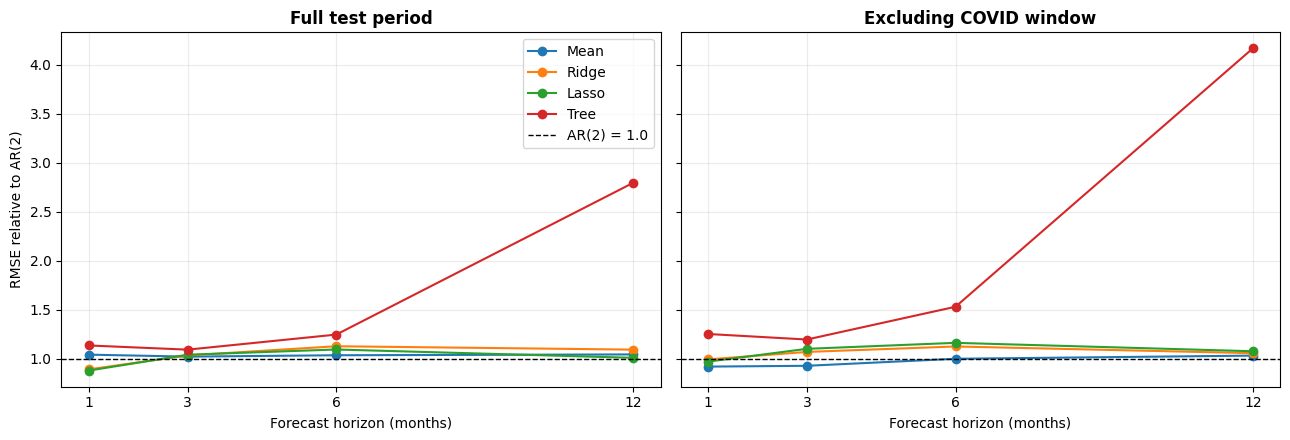

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, tbl, title in zip(axes, [rel_full, rel_nocovid],
                          ["Full test period", "Excluding COVID window"]):
    for model in ["Mean", "Ridge", "Lasso", "Tree"]:
        ax.plot(horizons, tbl.loc[model], marker="o", label=model)
    ax.axhline(1.0, color="black", linestyle="--", linewidth=1, label="AR(2) = 1.0")
    ax.set_title(title, fontweight="bold")
    ax.set_xlabel("Forecast horizon (months)")
    ax.set_xticks(horizons)
    ax.grid(alpha=0.25)
axes[0].set_ylabel("RMSE relative to AR(2)")
axes[0].legend()
plt.tight_layout()
plt.show()

### Interpretation

**No model consistently beats the AR(2) benchmark.** The only clear wins are at the one-month horizon on the full test sample, where Lasso and Ridge reduce RMSE by about 11–12% relative to AR(2) (relative RMSE of 0.88 and 0.89). From three months onward, both regularized models are worse than the benchmark on the full sample, by roughly 3–13%, except for Lasso at 12 months, which essentially ties (1.01).

**The one-month gain depends on 2020.** Excluding the COVID window, Ridge and Lasso fall to 0.99 and 0.97 at h = 1, which is roughly equal to the benchmark. A plausible reading is that same-month indicators such as jobless claims and financial stress signalled the shutdown immediately, which a model using only past industrial production could not, but this is an interpretation I have not tested directly.

**The benchmark itself is weak.** On the full sample, AR(2) beats the historical mean by only about 2–4%. Excluding COVID, the mean forecast actually beats AR(2) at h = 1 and h = 3 (relative RMSE of 0.92 and 0.93) and ties at h = 6. This suggests that the AR(2) relationship estimated on 1962–2009 data did not carry over well to the post-2010 period, and that industrial production growth is hard to predict from its own recent history. It also means that "relative to AR(2)" understates how hard the problem is: Ridge and Lasso do not beat the simple mean either once 2020 is removed.

**The regression tree performs worst, and badly at long horizons.** Its relative RMSE rises from 1.14 at h = 1 to 2.80 at h = 12 (4.17 excluding COVID). A tree with fixed split thresholds learned from pre-2010 data can issue extreme predictions when the post-2010 economy sits in a region of predictor space the training period associated with recessions. Its long-horizon failure is a warning about applying fixed thresholds to a changed economy, not evidence that nonlinear models are inherently worse.

**Caveats.** Differences of a few percent between models come from one test period and one train/test split, and no significance test (such as Diebold–Mariano) was run, so small gaps should not be over-read. The models are estimated once on pre-2010 data and not updated, so part of the deterioration at longer horizons may reflect parameter drift. The data are a revised vintage, not real-time releases.

**Takeaway.** For forecasting U.S. industrial production growth, adding 120 macro indicators with Ridge or Lasso did not reliably improve on a simple autoregression or even a historical mean beyond the one-month horizon. The regularized models were competitive only at very short horizons, and mostly because of the 2020 shock.